In [2]:
import pandas as pd
# Load your cleaned dataset for Project 2 EDA
df = pd.read_excel("Cleaned_Share_Dataset.xlsx")
# Display the first 5 rows to verify structure
display(df.head())
# Check data types and row ccount
df.info()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       1200 non-null   object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(

In [3]:
# Compute summary statistics for numerical columns
print(df.describe())
# Check the median seperately to comparw mean vs median skewness
print("\nMedian TotalPrice:", df['TotalPrice'].median())
print("Median UnitPrice:", df['UnitPrice'].median())

                      Date     Quantity    UnitPrice  ItemsInCart   TotalPrice
count                 1200  1200.000000  1200.000000  1200.000000  1200.000000
mean   2024-03-22 16:58:48     2.945833   356.412750     5.485000  1053.968300
min    2023-01-01 00:00:00     1.000000    11.390000     1.000000    11.390000
25%    2023-08-03 18:00:00     2.000000   186.062500     4.000000   410.520000
50%    2024-03-23 00:00:00     3.000000   364.210000     5.000000   823.615000
75%    2024-11-08 12:00:00     4.000000   521.570000     7.000000  1578.475000
max    2025-06-30 00:00:00     5.000000   699.930000    10.000000  3456.400000
std                    NaN     1.407557   197.177146     2.281983   819.856558

Median TotalPrice: 823.615
Median UnitPrice: 364.21


In [6]:
# Calculate IQR for TotalPrice to detect outliers
Q1 = df['TotalPrice'].quantile(0.25)
Q3 = df['TotalPrice'].quantile(0.75)
IQR = Q3 - Q1
# Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
#Filter outliers
outliers = df[(df['TotalPrice'] < lower_bound) | (df['TotalPrice'] > upper_bound)]
print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")
print(f"Number of outliers detected: {len(outliers)}")


Q1: 410.52, Q3: 1578.475, IQR: 1167.955
Lower Bound: -1341.4125, Upper Bound: 3330.4075
Number of outliers detected: 8


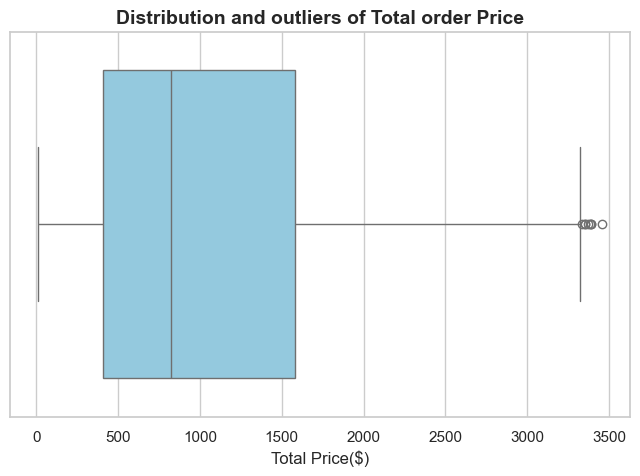

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
# Create a boxplot for TotalPrice
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['TotalPrice'], color='skyblue')
plt.title('Distribution and outliers of Total order Price', fontsize=14, fontweight='bold')
plt.xlabel('Total Price($)', fontsize=12)
# Show the plot
plt.show()
          
    
    

In [9]:
# Group Product to find total revenue and order count per category
product_summary = df.groupby('Product').agg(
    Total_Revenue=('TotalPrice', 'sum'),
    Order_Count=('OrderID', 'count'),
    Average_Order_Value=('TotalPrice', 'mean')
).reset_index().sort_values(by='Total_Revenue', ascending=False)
display(product_summary)

,Product,Total_Revenue,Order_Count,Average_Order_Value
0,Chair,195620.11,178,1098.989382
5,Printer,195612.61,181,1080.732652
2,Laptop,192126.56,173,1110.558150
6,Tablet,186568.95,179,1042.284637
3,Monitor,175651.41,163,1077.616012
1,Desk,167459.93,170,985.058412
4,Phone,151722.39,156,972.579423


In [10]:
product_summary.to_excel("Project2_Product_Summary.xlsx", index=False)
print("Saved successfully!")

Saved successfully!
